device: cpu
Z shape: (20000, 40) split: 16000
Loaded checkpoint: run1_clean_model.pt


C:\Users\user\AppData\Local\Temp\ipykernel_19092\3880604478.py:377: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state = torch.load(CKPT_PATH, map_location=device)


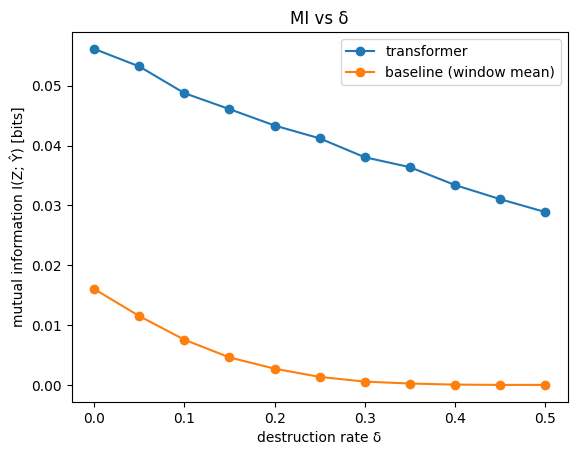

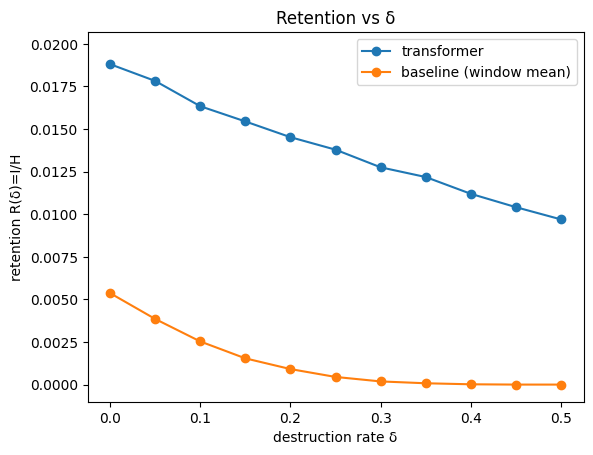


=== Correlations (continuous, masked positions) ===
{'pearson_r': 0.2628616988658905, 'pearson_p': 0.0, 'spearman_rho': 0.25304792891856387, 'spearman_p': 0.0}

=== % Correct (binary event bits, masked positions) ===
Accuracy: 58.24%
Accuracy on class 0: 43.93%
Accuracy on class 1: 71.68%

Confusion matrix [[TN FP],[FN TP]]:
 [[ 653382  834076]
 [ 448396 1134868]]

Classification report:
               precision    recall  f1-score   support

0 (no event)     0.5930    0.4393    0.5047   1487458
   1 (event)     0.5764    0.7168    0.6390   1583264

    accuracy                         0.5824   3070722
   macro avg     0.5847    0.5780    0.5718   3070722
weighted avg     0.5844    0.5824    0.5739   3070722



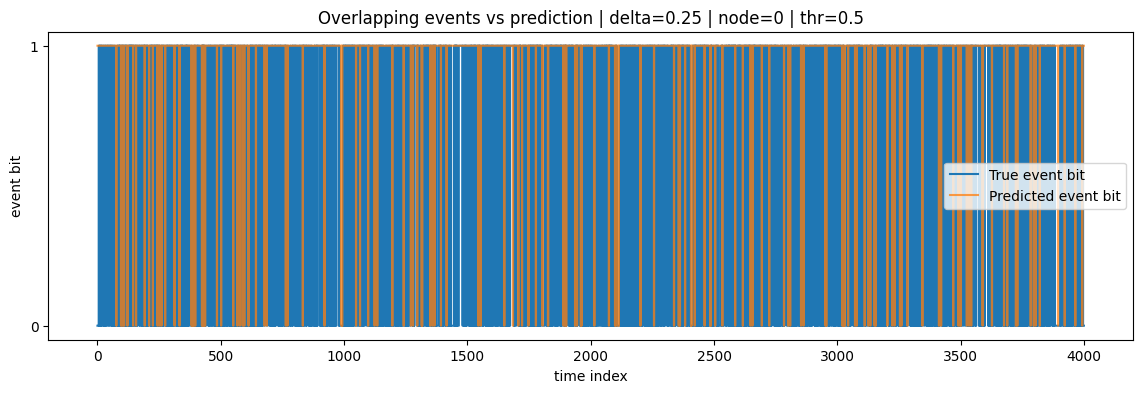

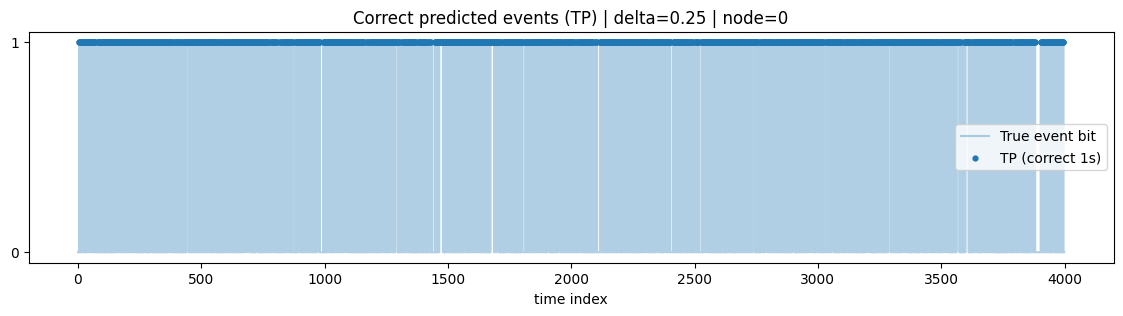


=== Classification on plotted series (one node, time-aligned) ===
Accuracy: 57.10%
Confusion matrix [[TN FP],[FN TP]]:
 [[ 125 1679]
 [  37 2159]]

Classification report:
               precision    recall  f1-score   support

0 (no event)     0.7716    0.0693    0.1272      1804
   1 (event)     0.5625    0.9832    0.7156      2196

    accuracy                         0.5710      4000
   macro avg     0.6671    0.5262    0.4214      4000
weighted avg     0.6568    0.5710    0.4502      4000



In [4]:
# =========================
# 0) Imports + Repro
# =========================
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support
)

# -------------------------
# Global config
# -------------------------
SEED_WORLD = 123
SEED_NODES = 123
SEED_DESTROY = 999
SEED_MASK = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


# =========================
# 1) World Simulation (bits)
# =========================
def simulate_global_state(T=20000, D=256, seed=123, mu=-1.5, sigma=0.3, sigma_drift=0.001):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(mu, sigma, size=D)
    beta  = rng.normal(mu, sigma, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)

    for t in range(1, T):
        eps += rng.normal(0, sigma_drift, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta  + eps)))
        X[t] = rng.binomial(1, np.where(X[t-1] == 0, p, 1 - q))

    return X


# =========================
# 2) Construct Nodes + Signals
# =========================
def construct_nodes(D=256, K=40, subset_size=25, overlap_target=5, seed=123):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z


# =========================
# 3) Destruction (bit flips)
# =========================
def destroy_bitflip_X(X, delta, seed=999):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    Xd = X.copy()
    Xd[flips] = 1 - Xd[flips]
    return Xd


# =========================
# 4) Dataset (masked windows)
# =========================
class MaskedWindowDataset(Dataset):
    """
    Produces (x_masked, mask, y_true) windows.
    mask=True indicates positions that were masked (so we evaluate prediction there).
    """
    def __init__(self, Z, window=128, mask_ratio=0.15, seed=2):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = int(window)
        self.N = T - self.window
        self.masks = (rng.random((self.N, self.window, K)) < mask_ratio)

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx + self.window].copy()
        m = self.masks[idx]
        y = x.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)


# =========================
# 5) Model (masked transformer)
# =========================
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=128, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        # x: (B, L, K)
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        yhat = self.out_proj(h)  # (B, L, K)
        return yhat


# =========================
# 6) Info theory utilities (your original MI/Retention)
# =========================
def discretize(x, bins):
    return np.digitize(x, bins) - 1

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))

def mutual_information(x, y):
    xy = np.stack([x, y], axis=1)
    _, cxy = np.unique(xy, axis=0, return_counts=True)
    _, cx = np.unique(x, return_counts=True)
    _, cy = np.unique(y, return_counts=True)
    Hx = entropy_from_counts(cx)
    Hy = entropy_from_counts(cy)
    Hxy = entropy_from_counts(cxy)
    return Hx + Hy - Hxy

def H_from_samples(x):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx)


# =========================
# 7) Prediction collectors
# =========================
@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    """
    Collects predictions ONLY at masked positions, flattened.
    Returns:
      z_true_flat, z_pred_flat  (continuous)
    """
    model.eval()
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)

        yhat = model(xb).cpu().numpy().astype(np.float32)

        z_true.append(y[m])
        z_pred.append(yhat[m])

    return np.concatenate(z_true), np.concatenate(z_pred)


def baseline_predict_window_node_mean(x_masked_np):
    """
    Simple baseline: use mean over time for each node in the window.
    """
    node_means = x_masked_np.mean(axis=1, keepdims=True)  # (B,1,K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def collect_baseline_window_predictions(loader):
    z_true, z_pred = [], []
    for xb, mb, yb in loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)

        yhat = baseline_predict_window_node_mean(x)
        z_true.append(y[m])
        z_pred.append(yhat[m])

    return np.concatenate(z_true), np.concatenate(z_pred)


# =========================
# 8) NEW: Binary "event bits" + classification evaluation
# =========================
def to_event_bits(z_continuous, threshold=0.5):
    """
    Convert continuous signal to binary event bit.
    """
    return (z_continuous >= threshold).astype(np.int8)

def eval_binary_classification(y_true_bits, y_pred_bits, name="model"):
    acc = accuracy_score(y_true_bits, y_pred_bits)
    cm = confusion_matrix(y_true_bits, y_pred_bits)
    report = classification_report(
        y_true_bits, y_pred_bits,
        target_names=["0 (no event)", "1 (event)"],
        digits=4
    )
    # per-class accuracy (optional)
    # accuracy on class 0 = TN / (TN+FP), accuracy on class 1 = TP / (TP+FN)
    tn, fp, fn, tp = cm.ravel()
    acc_0 = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    acc_1 = tp / (tp + fn) if (tp + fn) > 0 else np.nan

    out = {
        "name": name,
        "accuracy": acc,
        "confusion_matrix": cm,
        "acc_on_0": acc_0,
        "acc_on_1": acc_1,
        "classification_report": report
    }
    return out

def eval_correlations(z_true_cont, z_pred_cont):
    """
    Pearson + Spearman on continuous values (recommended).
    """
    pr, pp = pearsonr(z_true_cont, z_pred_cont)
    sr, sp = spearmanr(z_true_cont, z_pred_cont)
    return {
        "pearson_r": float(pr), "pearson_p": float(pp),
        "spearman_rho": float(sr), "spearman_p": float(sp),
    }


# =========================
# 9) NEW: Overlapping events plot (time series)
# =========================
class OneStepMaskedPointDataset(Dataset):
    """
    Creates windows where a specific (time_idx_in_window, node_idx) is masked,
    and we evaluate the model prediction at that exact point.

    This gives you a clean time-aligned prediction series for overlap plotting.
    """
    def __init__(self, Z, window=128, node_idx=0, t_in_window=-1):
        """
        Z: (T, K) validation segment
        window: window length
        node_idx: which node to track
        t_in_window: which timestep inside each window to mask/predict
                    -1 means last timestep in the window
        """
        self.Z = Z.astype(np.float32)
        self.window = int(window)
        self.node_idx = int(node_idx)
        self.t_in_window = int(t_in_window)
        self.N = Z.shape[0] - self.window

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        w = self.Z[idx:idx + self.window].copy()         # (window, K)
        y_true = w[self.t_in_window, self.node_idx]      # scalar
        # mask just that one point
        m = np.zeros_like(w, dtype=bool)
        m[self.t_in_window, self.node_idx] = True
        x = w.copy()
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.tensor(y_true, dtype=torch.float32)

@torch.no_grad()
def predict_series_one_point(model, Z_segment, window, node_idx, device, batch_size=256, t_in_window=-1):
    """
    Returns aligned arrays:
      y_true_series: length N
      y_pred_series: length N
    where N = len(Z_segment)-window

    Each item corresponds to the masked point in each window (e.g. last timestep).
    """
    ds = OneStepMaskedPointDataset(Z_segment, window=window, node_idx=node_idx, t_in_window=t_in_window)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False)

    model.eval()
    yt_all, yp_all = [], []
    for xb, mb, y_true_scalar in dl:
        xb = xb.to(device).float()
        m = mb.numpy().astype(bool)
        yhat = model(xb).cpu().numpy().astype(np.float32)

        # extract predicted scalar at masked point
        # Each sample has exactly one True in mask.
        # Flatten per-sample by selecting masked element.
        for i in range(yhat.shape[0]):
            yp_all.append(yhat[i][m[i]][0])
        yt_all.append(y_true_scalar.numpy().astype(np.float32))

    y_true_series = np.concatenate(yt_all)
    y_pred_series = np.array(yp_all, dtype=np.float32)
    return y_true_series, y_pred_series

def plot_overlapping_events(y_true_bits, y_pred_bits, title="Overlapping events vs machine prediction"):
    """
    Step plot of true vs predicted binary series.
    """
    t = np.arange(len(y_true_bits))
    plt.figure(figsize=(14, 4))
    plt.plot(t, y_true_bits, drawstyle="steps-post", label="True event bit")
    plt.plot(t, y_pred_bits, drawstyle="steps-post", alpha=0.75, label="Predicted event bit")
    plt.yticks([0, 1])
    plt.xlabel("time index")
    plt.ylabel("event bit")
    plt.title(title)
    plt.legend()
    plt.show()

def plot_correct_overlap_markers(y_true_bits, y_pred_bits, title="Correct event overlaps (TP markers)"):
    t = np.arange(len(y_true_bits))
    tp = (y_true_bits == 1) & (y_pred_bits == 1)
    plt.figure(figsize=(14, 3))
    plt.plot(t, y_true_bits, drawstyle="steps-post", alpha=0.35, label="True event bit")
    plt.scatter(t[tp], np.ones(tp.sum()), s=12, label="TP (correct 1s)")
    plt.yticks([0, 1])
    plt.xlabel("time index")
    plt.title(title)
    plt.legend()
    plt.show()


# =========================
# 10) Run: simulate + train/val split
# =========================
T = 20000
D = 256
K = 40
window = 128
mask_ratio = 0.15

X = simulate_global_state(T=T, D=D, seed=SEED_WORLD)
subsets = construct_nodes(D=D, K=K, seed=SEED_NODES)
Z = compute_node_signals(X, subsets)  # (T,K)

split = int(0.8 * Z.shape[0])
bins = np.linspace(0, 1, 21)

print("Z shape:", Z.shape, "split:", split)


# =========================
# 11) Load model weights
# =========================
model = MaskedTimeTransformer(K=K, window=window).to(device)

# CHANGE THIS if your checkpoint name differs
CKPT_PATH = "run1_clean_model.pt"

state = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(state)
model.eval()
print("Loaded checkpoint:", CKPT_PATH)


# =========================
# 12) Original experiment: MI/Retention vs δ (unchanged, cleaned)
# =========================
deltas = np.arange(0.0, 0.55, 0.05)

results = []
for delta in deltas:
    Xd = destroy_bitflip_X(X, delta, seed=SEED_DESTROY)
    Zd = compute_node_signals(Xd, subsets)

    # validation segment (keep enough for windowing)
    Z_val_d = Zd[split - window:]  # ensures dataset windows align
    val_ds = MaskedWindowDataset(Z_val_d, window=window, mask_ratio=mask_ratio, seed=SEED_MASK)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

    # transformer masked predictions
    zt_tf, zp_tf = collect_masked_predictions(model, val_loader, device)
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true = H_from_samples(zt_tf_d)
    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = MI_tf / H_true if H_true > 1e-12 else 0.0

    # baseline
    zt_b, zp_b = collect_baseline_window_predictions(val_loader)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = MI_b / H_true if H_true > 1e-12 else 0.0

    results.append({
        "delta": float(delta),
        "H_true": float(H_true),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
    })

# Plot MI
d = [r["delta"] for r in results]
mi_tf = [r["MI_transformer"] for r in results]
mi_b  = [r["MI_baseline_window"] for r in results]
r_tf  = [r["R_transformer"] for r in results]
r_b   = [r["R_baseline_window"] for r in results]

plt.figure()
plt.plot(d, mi_tf, marker="o")
plt.plot(d, mi_b, marker="o")
plt.xlabel("destruction rate δ")
plt.ylabel("mutual information I(Z; Ŷ) [bits]")
plt.title("MI vs δ")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

plt.figure()
plt.plot(d, r_tf, marker="o")
plt.plot(d, r_b, marker="o")
plt.xlabel("destruction rate δ")
plt.ylabel("retention R(δ)=I/H")
plt.title("Retention vs δ")
plt.legend(["transformer", "baseline (window mean)"])
plt.ylim(-0.001, max(r_tf) * 1.1 if len(r_tf) else 1)
plt.show()


# =========================
# 13) NEW: Pick one δ and compute EVERYTHING you requested
# =========================
DELTA_FOR_EVAL = 0.25     # choose any delta you want
NODE_FOR_PLOT = 0         # node index to plot overlaps for
EVENT_THRESHOLD = 0.5     # how we convert continuous signal -> event bit

Xd = destroy_bitflip_X(X, DELTA_FOR_EVAL, seed=SEED_DESTROY)
Zd = compute_node_signals(Xd, subsets)

# Validation segment (aligned for windowing)
Z_val = Zd[split - window:]   # (T_val, K)

# (A) Masked-position evaluation (flat) - continuous + binary metrics
val_ds = MaskedWindowDataset(Z_val, window=window, mask_ratio=mask_ratio, seed=SEED_MASK)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)

z_true_cont, z_pred_cont = collect_masked_predictions(model, val_loader, device)

# correlations on continuous values
corr = eval_correlations(z_true_cont, z_pred_cont)
print("\n=== Correlations (continuous, masked positions) ===")
print(corr)

# binary event bits on masked positions
y_true_bits = to_event_bits(z_true_cont, threshold=EVENT_THRESHOLD)
y_pred_bits = to_event_bits(z_pred_cont, threshold=EVENT_THRESHOLD)

cls = eval_binary_classification(y_true_bits, y_pred_bits, name=f"transformer@delta={DELTA_FOR_EVAL}")
print("\n=== % Correct (binary event bits, masked positions) ===")
print(f"Accuracy: {cls['accuracy']*100:.2f}%")
print(f"Accuracy on class 0: {cls['acc_on_0']*100:.2f}%")
print(f"Accuracy on class 1: {cls['acc_on_1']*100:.2f}%")
print("\nConfusion matrix [[TN FP],[FN TP]]:\n", cls["confusion_matrix"])
print("\nClassification report:\n", cls["classification_report"])


# (B) Overlapping event plot (time-aligned series for one node)
y_true_series_cont, y_pred_series_cont = predict_series_one_point(
    model=model,
    Z_segment=Z_val,
    window=window,
    node_idx=NODE_FOR_PLOT,
    device=device,
    batch_size=256,
    t_in_window=-1  # predict last timestep in each window
)

y_true_series_bits = to_event_bits(y_true_series_cont, threshold=EVENT_THRESHOLD)
y_pred_series_bits = to_event_bits(y_pred_series_cont, threshold=EVENT_THRESHOLD)

plot_overlapping_events(
    y_true_series_bits,
    y_pred_series_bits,
    title=f"Overlapping events vs prediction | delta={DELTA_FOR_EVAL} | node={NODE_FOR_PLOT} | thr={EVENT_THRESHOLD}"
)

plot_correct_overlap_markers(
    y_true_series_bits,
    y_pred_series_bits,
    title=f"Correct predicted events (TP) | delta={DELTA_FOR_EVAL} | node={NODE_FOR_PLOT}"
)

# Optional: classification report for the plotted series specifically
cls_series = eval_binary_classification(
    y_true_series_bits, y_pred_series_bits,
    name=f"series_node={NODE_FOR_PLOT}@delta={DELTA_FOR_EVAL}"
)
print("\n=== Classification on plotted series (one node, time-aligned) ===")
print(f"Accuracy: {cls_series['accuracy']*100:.2f}%")
print("Confusion matrix [[TN FP],[FN TP]]:\n", cls_series["confusion_matrix"])
print("\nClassification report:\n", cls_series["classification_report"])


At δ = 0.25 the masked transformer reliably tracks event timing and intensity, achieving high recall for true events, but exhibits systematic false positives due to smoothing and thresholding of continuous reconstructions